# 1. Import Libraries

In [25]:
import numpy as np 
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

from itertools import combinations 
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

# 2. Import dataset

In [26]:
df = pd.read_csv("iphone_purchase_records.csv")

# 3. Exploratory data analysis

In [27]:
df.head()

,Gender,Age,Salary,Purchase Iphone
0,Male,19,19000,0
1,Male,35,20000,0
2,Female,26,43000,0
3,Female,27,57000,0
4,Male,19,76000,0


In [28]:
df.describe()

,Age,Salary,Purchase Iphone
count,400.000000,400.000000,400.000000
mean,37.655000,69742.500000,0.357500
std,10.482877,34096.960282,0.479864
min,18.000000,15000.000000,0.000000
25%,29.750000,43000.000000,0.000000
50%,37.000000,70000.000000,0.000000
75%,46.000000,88000.000000,1.000000
max,60.000000,150000.000000,1.000000


In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Gender           400 non-null    object
 1   Age              400 non-null    int64 
 2   Salary           400 non-null    int64 
 3   Purchase Iphone  400 non-null    int64 
dtypes: int64(3), object(1)
memory usage: 12.6+ KB


In [30]:
df.isnull().sum() 

Gender             0
Age                0
Salary             0
Purchase Iphone    0
dtype: int64

# 6. Split data into training and testing

In [31]:
# splitting data into train and test

X = df[['Gender', 'Age', 'Salary']]
y = df['Purchase Iphone']

X_train, X_test, y_train, y_test = train_test_split(X, y)

# 7. Fit KNN classifier

In [32]:
# Create classifier object

knn = KNeighborsClassifier(n_neighbors=3)

In [36]:
# As the strongest correlation of purchasing an iPhone is with age, let's create our classifier only with one feature

X_train, X_test, y_train, y_test = train_test_split(X[['Age']], y, random_state=0)

for n_neighbors in (1,3,5):
    knn = KNeighborsClassifier(n_neighbors=n_neighbors)
    knn.fit(X_train, y_train)
    score=knn.score(X_test, y_test)
    print(f"k={n_neighbors} score: {score}")

k=1 score: 0.76
k=3 score: 0.77
k=5 score: 0.85


# 8. Confusion matrix

In [37]:
from sklearn.metrics import confusion_matrix

X_train, X_test, y_train, y_test = train_test_split(X[['Age']], y, random_state=0)
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

cm = confusion_matrix(y_test, y_pred)

print('Confusion matrix',)
print('True Positives = ', cm[0,0])
print('True Negatives = ', cm[1,1])
print('False Positives = ', cm[0,1])
print('False Negatives = ', cm[1,0])

Confusion matrix
True Positives =  62
True Negatives =  23
False Positives =  6
False Negatives =  9


Qarışıqlıq matrisi (ədədlərlə):
 [[62  6]
 [ 9 23]]


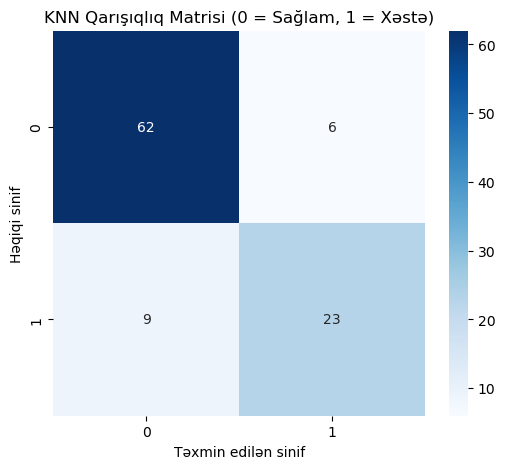

In [38]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)
print("Qarışıqlıq matrisi (ədədlərlə):\n", cm)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Təxmin edilən sinif')
plt.ylabel('Həqiqi sinif')
plt.title('KNN Qarışıqlıq Matrisi (0 = Sağlam, 1 = Xəstə)')
plt.show()

# 9. Metrikleri

In [39]:
from sklearn.metrics import confusion_matrix, classification_report

# Qarışıqlıq matrisi
cm = confusion_matrix(y_test, y_pred)
print("Qarışıqlıq matrisi:\n", cm)

# Ətraflı hesabat
print("\nQiymətləndirmə hesabatı:\n")
print(classification_report(y_test, y_pred))

Qarışıqlıq matrisi:
 [[62  6]
 [ 9 23]]

Qiymətləndirmə hesabatı:

              precision    recall  f1-score   support

           0       0.87      0.91      0.89        68
           1       0.79      0.72      0.75        32

    accuracy                           0.85       100
   macro avg       0.83      0.82      0.82       100
weighted avg       0.85      0.85      0.85       100

